In [4]:

import pandas as pd
from io import StringIO

csv_data = """period,revenue_rm_million
2022-Q1,905.163
2022-Q2,1048.734
2022-Q3,966.165
2022-Q4,1065.780
2023-Q1,1046.401
2023-Q2,1099.638
2023-Q3,1066.532
2023-Q4,1146.718
2024-Q1,1143.051
2024-Q2,1196.228
2024-Q3,1135.074
2024-Q4,1177.063
2025-Q1,1257.178
2025-Q2,1214.197
2025-Q3,1198.459
2025-Q4,1284.123
2026-Q1,1373.732
2026-Q2,1257.314
"""

df = pd.read_csv(StringIO(csv_data))

print("Dataset shape:", df.shape)
display(df.head())

# Optional: recreate the CSV file
df.to_csv("MRDIY_Colab_Revenue.csv", index=False)


Dataset shape: (18, 2)


,period,revenue_rm_million
0,2022-Q1,905.163
1,2022-Q2,1048.734
2,2022-Q3,966.165
3,2022-Q4,1065.780
4,2023-Q1,1046.401


Task 2.2A — Check missing values, duplicates and data types

In [5]:

# Task 2.2A: Initial data quality checks

print("DATASET INFORMATION")
df.info()

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

print("\nDUPLICATE PERIODS")
print(df["period"].duplicated().sum())

print("\nDATA TYPES")
print(df.dtypes)


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 2 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   period              18 non-null     object 
 1   revenue_rm_million  18 non-null     float64
dtypes: float64(1), object(1)
memory usage: 420.0+ bytes

MISSING VALUES
period                0
revenue_rm_million    0
dtype: int64

DUPLICATE ROWS
0

DUPLICATE PERIODS
0

DATA TYPES
period                 object
revenue_rm_million    float64
dtype: object


Task 2.2B — Verify chronological order and quarterly continuity

In [6]:

# Task 2.2B: Verify chronological order and continuity

# Convert period labels into quarterly time periods
df["quarter_date"] = pd.PeriodIndex(
    df["period"], freq="Q-DEC"
)

# Check whether records are chronologically ordered
is_sorted = df["quarter_date"].is_monotonic_increasing

# Generate the expected sequence of quarters
expected_quarters = pd.period_range(
    start=df["quarter_date"].min(),
    end=df["quarter_date"].max(),
    freq="Q-DEC"
)

# Identify any missing quarters
missing_quarters = expected_quarters.difference(
    pd.PeriodIndex(df["quarter_date"])
)

print("CHRONOLOGICAL ORDER")
print("Already sorted:", is_sorted)

print("\nQUARTERLY CONTINUITY")
print("First quarter:", df["quarter_date"].min())
print("Last quarter:", df["quarter_date"].max())
print("Expected number of quarters:", len(expected_quarters))
print("Actual number of quarters:", len(df))
print("Missing quarters:", list(missing_quarters))


CHRONOLOGICAL ORDER
Already sorted: True

QUARTERLY CONTINUITY
First quarter: 2022Q1
Last quarter: 2026Q2
Expected number of quarters: 18
Actual number of quarters: 18
Missing quarters: []


ask 2.2C — Final Revenue Validation

In [7]:

# Task 2.2C: Final Revenue Validation

print("REVENUE VALIDATION")

# Check for zero or negative revenue
invalid_revenue = (df["revenue_rm_million"] <= 0).sum()

print("Zero or negative revenue values:", invalid_revenue)

# Check revenue statistics
print("\nREVENUE SUMMARY (RM MILLION)")
print(df["revenue_rm_million"].describe().round(3))

# Check the complete dataset
print("\nCOMPLETE DATASET")
display(df[["period", "revenue_rm_million"]])


REVENUE VALIDATION
Zero or negative revenue values: 0

REVENUE SUMMARY (RM MILLION)
count      18.000
mean     1143.419
std       116.623
min       905.163
25%      1065.968
50%      1144.884
75%      1210.262
max      1373.732
Name: revenue_rm_million, dtype: float64

COMPLETE DATASET


,period,revenue_rm_million
0,2022-Q1,905.163
1,2022-Q2,1048.734
2,2022-Q3,966.165
3,2022-Q4,1065.780
4,2023-Q1,1046.401
5,2023-Q2,1099.638
6,2023-Q3,1066.532
7,2023-Q4,1146.718
8,2024-Q1,1143.051
9,2024-Q2,1196.228


Task 2.3A: Historical Quarterly Revenue Trend

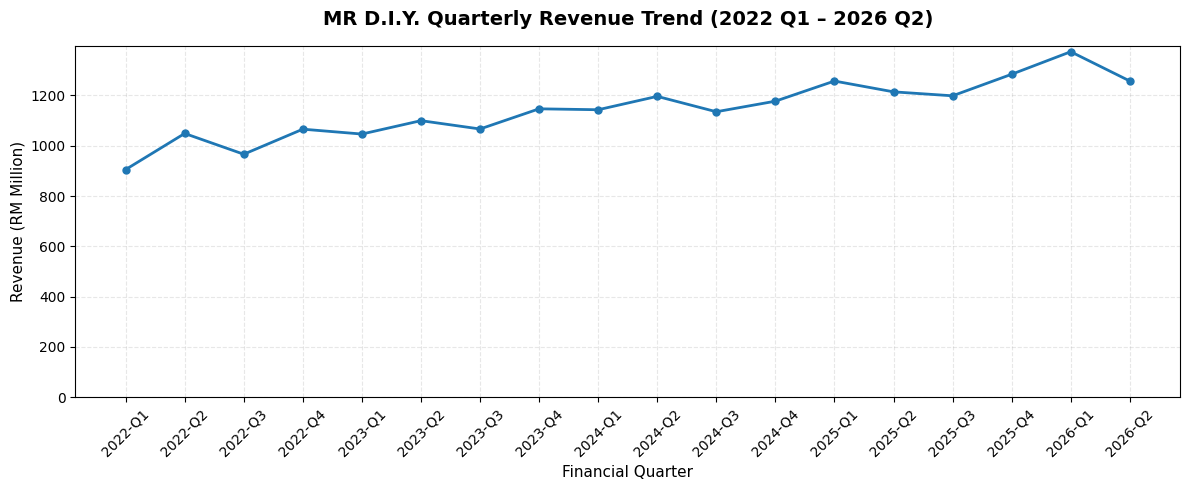

In [8]:

# Task 2.3A: Historical Quarterly Revenue Trend

import matplotlib.pyplot as plt

# Prepare the values
quarters = df["period"]
revenue = df["revenue_rm_million"]

# Create the figure
fig, ax = plt.subplots(figsize=(12, 5))

# Plot quarterly revenue
ax.plot(
    quarters,
    revenue,
    marker="o",
    linewidth=2,
    markersize=5
)

# Add chart title and axis labels
ax.set_title(
    "MR D.I.Y. Quarterly Revenue Trend (2022 Q1 – 2026 Q2)",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Financial Quarter", fontsize=11)
ax.set_ylabel("Revenue (RM Million)", fontsize=11)

# Improve readability
ax.grid(True, linestyle="--", alpha=0.3)
ax.tick_params(axis="x", rotation=45)
ax.set_ylim(bottom=0)

# Adjust layout
plt.tight_layout()

# Save high-quality image for report and poster
plt.savefig(
    "MRDIY_EDA1_Revenue_Trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Task 2.3B — EDA 2: Quarterly Revenue Comparison by Year

QUARTERLY REVENUE COMPARISON (RM MILLION)


year,2022,2023,2024,2025
quarter,,,,
Q1,905.163,1046.401,1143.051,1257.178
Q2,1048.734,1099.638,1196.228,1214.197
Q3,966.165,1066.532,1135.074,1198.459
Q4,1065.780,1146.718,1177.063,1284.123


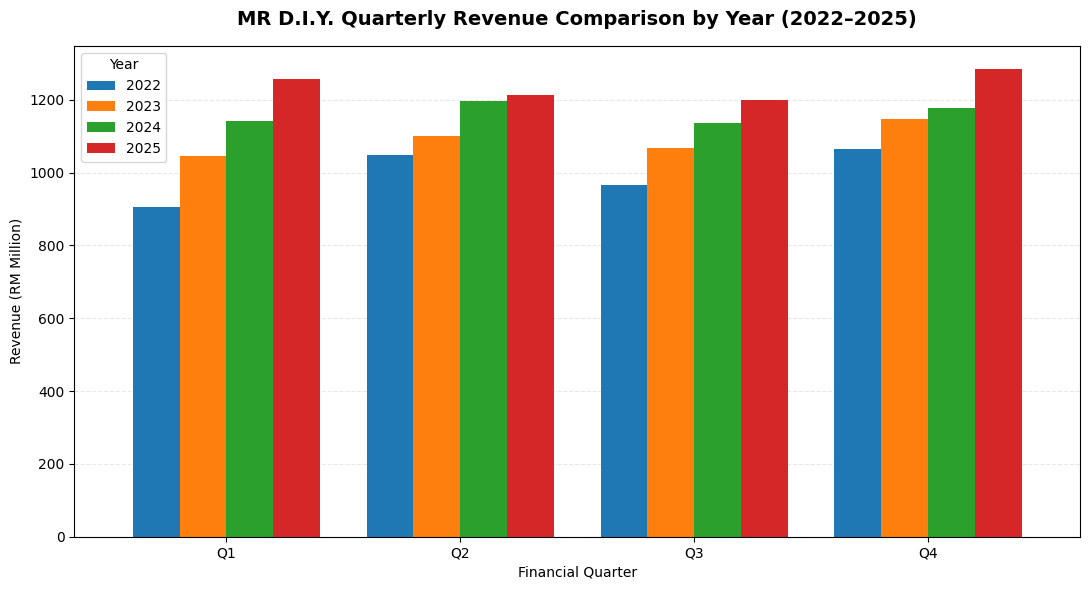

In [9]:

# Task 2.3B: Quarterly Revenue Comparison by Year

import pandas as pd
import matplotlib.pyplot as plt

# Create a separate dataset for EDA
eda_df = df[["period", "revenue_rm_million"]].copy()

# Extract year and quarter
eda_df[["year", "quarter"]] = eda_df["period"].str.split(
    "-", expand=True
)

eda_df["year"] = eda_df["year"].astype(int)

# Include only complete financial years
complete_years = eda_df.groupby("year").filter(
    lambda x: len(x) == 4
)

# Create pivot table
quarterly_comparison = complete_years.pivot(
    index="quarter",
    columns="year",
    values="revenue_rm_million"
)

# Arrange quarters chronologically
quarterly_comparison = quarterly_comparison.reindex(
    ["Q1", "Q2", "Q3", "Q4"]
)

print("QUARTERLY REVENUE COMPARISON (RM MILLION)")
display(quarterly_comparison)

# Create grouped bar chart
ax = quarterly_comparison.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

ax.set_title(
    "MR D.I.Y. Quarterly Revenue Comparison by Year (2022–2025)",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Financial Quarter")
ax.set_ylabel("Revenue (RM Million)")

ax.legend(title="Year")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.xticks(rotation=0)
plt.tight_layout()

# Save high-resolution chart
plt.savefig(
    "MRDIY_EDA2_Quarterly_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Task 2.3C: Quarterly Revenue Growth Analysis

QUARTERLY REVENUE GROWTH ANALYSIS


,period,revenue_rm_million,QoQ_Growth_%,YoY_Growth_%
0,2022-Q1,905.16,NaN,NaN
1,2022-Q2,1048.73,15.86,NaN
2,2022-Q3,966.16,-7.87,NaN
3,2022-Q4,1065.78,10.31,NaN
4,2023-Q1,1046.40,-1.82,15.60
5,2023-Q2,1099.64,5.09,4.85
6,2023-Q3,1066.53,-3.01,10.39
7,2023-Q4,1146.72,7.52,7.59
8,2024-Q1,1143.05,-0.32,9.24
9,2024-Q2,1196.23,4.65,8.78


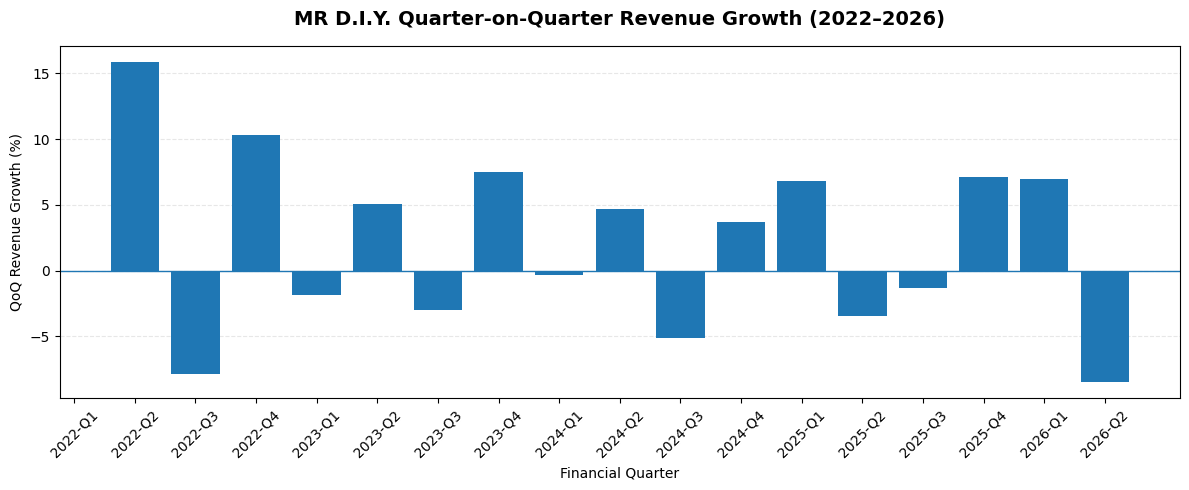

In [10]:

# Task 2.3C: Quarterly Revenue Growth Analysis

import pandas as pd
import matplotlib.pyplot as plt

# Create a copy of the dataset
growth_df = df[
    ["period", "revenue_rm_million"]
].copy()

# Calculate quarter-on-quarter growth
growth_df["QoQ_Growth_%"] = (
    growth_df["revenue_rm_million"]
    .pct_change(periods=1) * 100
)

# Calculate year-on-year growth
growth_df["YoY_Growth_%"] = (
    growth_df["revenue_rm_million"]
    .pct_change(periods=4) * 100
)

# Display growth analysis
print("QUARTERLY REVENUE GROWTH ANALYSIS")
display(growth_df.round(2))

# Create QoQ growth chart
fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(
    growth_df["period"],
    growth_df["QoQ_Growth_%"]
)

ax.axhline(0, linewidth=1)

ax.set_title(
    "MR D.I.Y. Quarter-on-Quarter Revenue Growth (2022–2026)",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Financial Quarter")
ax.set_ylabel("QoQ Revenue Growth (%)")

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
ax.tick_params(axis="x", rotation=45)

plt.tight_layout()

# Save chart
plt.savefig(
    "MRDIY_EDA3_QoQ_Growth.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Task 2.4A — Export the final CSV files

In [11]:

# Task 2.4A: Export final datasets

# Main dataset for forecasting and Streamlit
final_revenue = df[
    ["period", "revenue_rm_million"]
].copy()

final_revenue.to_csv(
    "MRDIY_Cleaned_Revenue.csv",
    index=False
)

# Supporting EDA growth dataset
growth_df.to_csv(
    "MRDIY_Revenue_Growth_Analysis.csv",
    index=False
)

print("Files exported successfully!")

print("\nMain dataset:")
display(final_revenue.head())

print("\nSupporting dataset:")
display(growth_df.head())


Files exported successfully!

Main dataset:


,period,revenue_rm_million
0,2022-Q1,905.163
1,2022-Q2,1048.734
2,2022-Q3,966.165
3,2022-Q4,1065.780
4,2023-Q1,1046.401



Supporting dataset:


,period,revenue_rm_million,QoQ_Growth_%,YoY_Growth_%
0,2022-Q1,905.163,NaN,NaN
1,2022-Q2,1048.734,15.861342,NaN
2,2022-Q3,966.165,-7.873207,NaN
3,2022-Q4,1065.780,10.310351,NaN
4,2023-Q1,1046.401,-1.818293,15.603598


In [12]:

from google.colab import files

files.download("MRDIY_Cleaned_Revenue.csv")
files.download("MRDIY_Revenue_Growth_Analysis.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>